<a href="https://colab.research.google.com/github/ashishkunche9-lab/blockchain-projects/blob/main/03-proof-of-work/proof_of_work.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import hashlib, time

def mine(data, difficulty):
    prefix = "0" * difficulty
    nonce = 0
    start = time.time()
    while True:
        digest = hashlib.sha256(f"{data}{nonce}".encode()).hexdigest()
        if digest.startswith(prefix):
            return nonce, digest, time.time() - start
        nonce += 1

data = "Alarm: Vibration 8.2 mm/s"
print(f"{'Difficulty':<11}{'Attempts':>10}{'Time (s)':>10}   Hash")
for d in range(1, 6):
    nonce, digest, secs = mine(data, d)
    print(f"{d:<11}{nonce + 1:>10}{secs:>10.2f}   {digest[:24]}...")

Difficulty   Attempts  Time (s)   Hash
1                   5      0.00   082ed9c561b5a858b01e76e8...
2                 123      0.00   00536ad0e05f2ee22e2f8856...
3                5036      0.01   00075ce8faf6bfff50e37fd5...
4              205803      0.29   0000166a9c6057e8e8235a63...
5              808547      1.45   00000eb60cd1bbcf11de7313...


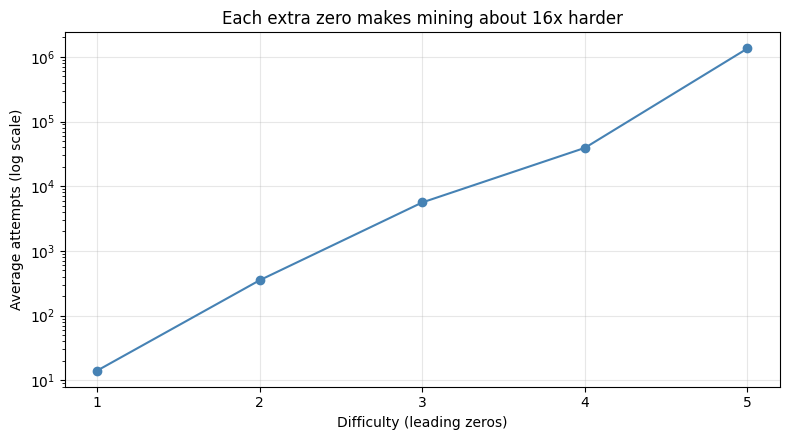

In [2]:
import matplotlib.pyplot as plt

levels = [1, 2, 3, 4, 5]
avg_attempts = []
for d in levels:
    tries = [mine(f"alarm-{k}", d)[0] + 1 for k in range(8)]
    avg_attempts.append(sum(tries) / len(tries))

plt.figure(figsize=(8, 4.5))
plt.plot(levels, avg_attempts, marker="o", color="steelblue")
plt.yscale("log")
plt.xticks(levels)
plt.xlabel("Difficulty (leading zeros)")
plt.ylabel("Average attempts (log scale)")
plt.title("Each extra zero makes mining about 16x harder")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [3]:
DIFF = 5   # slow ga unte 4 ki marchu

def mine_block(index, data, prev_hash):
    nonce = 0
    while True:
        digest = hashlib.sha256(f"{index}{data}{prev_hash}{nonce}".encode()).hexdigest()
        if digest.startswith("0" * DIFF):
            return {"index": index, "data": data, "prev_hash": prev_hash,
                    "nonce": nonce, "hash": digest}
        nonce += 1

def is_valid(chain):
    for i, b in enumerate(chain):
        calc = hashlib.sha256(
            f"{b['index']}{b['data']}{b['prev_hash']}{b['nonce']}".encode()).hexdigest()
        if calc != b["hash"] or not calc.startswith("0" * DIFF):
            return False
        if i > 0 and b["prev_hash"] != chain[i - 1]["hash"]:
            return False
    return True

alarms = ["Vibration 8.2", "Bearing temp 91", "Oil pressure 1.2",
          "Vibration 7.9", "Bearing temp 88", "Oil pressure 1.4"]

# Honest: build the chain
chain, t0 = [], time.time()
for i, a in enumerate(alarms):
    prev = chain[-1]["hash"] if chain else "0" * 64
    chain.append(mine_block(i, a, prev))
honest = time.time() - t0
print(f"Honest chain of {len(chain)} blocks mined in {honest:.1f}s | valid: {is_valid(chain)}")

# Attacker edits block 1 without re-mining
chain[1]["data"] = "Vibration 2.0"
print(f"\nAttacker edits block 1, no re-mining -> valid: {is_valid(chain)}")

# Attacker re-mines block 1 and every block after it
t0 = time.time()
for i in range(1, len(chain)):
    prev = chain[i - 1]["hash"]
    chain[i] = mine_block(i, chain[i]["data"], prev)
attack = time.time() - t0
print(f"Attacker re-mines blocks 1 to {len(chain) - 1} -> valid: {is_valid(chain)}")
print(f"Attack cost: {attack:.1f}s of work for ONE edit")

Honest chain of 6 blocks mined in 14.9s | valid: True

Attacker edits block 1, no re-mining -> valid: False
Attacker re-mines blocks 1 to 5 -> valid: True
Attack cost: 11.9s of work for ONE edit
